In [1]:
%load_ext autoreload
%autoreload 2

import sys
import importlib
from pathlib import Path
import cv2
import numpy as np

# Resolve paths
PROJECT_ROOT = Path("..").resolve()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))

# Import pipeline classes and utilities
from dataset import ImageDataset
from feature_matching import FeatureMatcher
from pose_estimation import PoseEstimator
from triangulation import Triangulator
from bundle_adjustment import BundleAdjuster
from utils import build_intrinsic_matrix, export_ply

In [2]:
# 1. Load Dataset
dataset = ImageDataset()
print(f"Loaded {len(dataset)} images.")

# 2. Build Intrinsic Matrix K
height, width = dataset[0].shape[:2]
K = build_intrinsic_matrix(width=width, height=height)

# 3. Instantiate Pipeline Modules
matcher = FeatureMatcher()
estimator = PoseEstimator(K)
triangulator = Triangulator(K)
optimizer = BundleAdjuster(K)

# 4. Process Seed Pair (Image 0 and Image 1)
img0, img1 = dataset[0], dataset[1]
kp0, des0 = matcher.extract_features(img0)
kp1, des1 = matcher.extract_features(img1)

good_matches = matcher.filter_matches_lowe(matcher.match_features(des0, des1))
pts0, pts1 = estimator.extract_match_coordinates(kp0, kp1, good_matches)

# Recover Initial Pose & Triangulate Initial 3D Points
E, ransac_mask = estimator.estimate_essential_matrix(pts0, pts1)
R1, T1 = estimator.recover_camera_pose(E, pts0, pts1, ransac_mask)

inlier_idx = (ransac_mask.ravel() == 1)
pts0_in, pts1_in = pts0[inlier_idx], pts1[inlier_idx]

P0, P1 = triangulator.construct_projection_matrices(np.eye(3), np.zeros((3, 1)))
_, P1_rel = triangulator.construct_projection_matrices(R1, T1)

pts3D_raw = triangulator.triangulate_points(P0, P1_rel, pts0_in, pts1_in)
pts3D_init, cheirality_mask = triangulator.filter_cheirality(pts3D_raw, R1, T1)

# Refine Baseline with 2-View Bundle Adjustment
pts3D_opt, R1_opt, T1_opt, init_rmse = optimizer.optimize_2view(
    pts3D_init=pts3D_init,
    R_init=R1,
    T_init=T1,
    pts1_2d=pts0_in[cheirality_mask],
    pts2_2d=pts1_in[cheirality_mask]
)

print(f"Baseline Seed Initialized: {len(pts3D_opt)} 3D points | RMSE: {init_rmse:.4f} px")

Loaded 136 images.
Baseline Seed Initialized: 537 3D points | RMSE: 0.1215 px


In [5]:
# Master Map Containers
registered_cameras = {
    0: {"R": np.eye(3), "T": np.zeros((3, 1)), "kp": kp0, "des": des0},
    1: {"R": R1_opt, "T": T1_opt, "kp": kp1, "des": des1}
}

# Unified 3D Point Cloud Map
global_point_cloud = pts3D_opt.copy()

# 1. Extract the 635 descriptors corresponding to good_matches in Image 1
des1_matched = np.array([des1[m.trainIdx] for m in good_matches])

# 2. Filter down through the RANSAC mask and Cheirality mask
registered_descriptors = des1_matched[inlier_idx][cheirality_mask]

print(f"Registered Map Initialized with {len(global_point_cloud)} 3D points and matching descriptors.")

Registered Map Initialized with 537 3D points and matching descriptors.


In [7]:
print("Starting Incremental SfM Reconstruction across remaining views...")

for idx in range(2, len(dataset)):
    curr_img = dataset[idx]
    kp_curr, des_curr = matcher.extract_features(curr_img)
    
    # 1. Match current image against established 3D map descriptors
    map_matches = matcher.filter_matches_lowe(matcher.match_features(des_curr, registered_descriptors))
    
    if len(map_matches) < 15:
        print(f"Skipping Image {idx}: Insufficient 3D-to-2D correspondences ({len(map_matches)})")
        continue

    # 2. Extract 2D image coordinates and corresponding 3D world points
    pts2D = np.float32([kp_curr[m.queryIdx].pt for m in map_matches])
    pts3D_assoc = np.float32([global_point_cloud[m.trainIdx] for m in map_matches])

    # 3. Solve Camera Pose via Perspective-n-Point (PnP)
    success, rvec, tvec, pnp_inliers = cv2.solvePnPRansac(
        pts3D_assoc, pts2D, K, distCoeffs=None, flags=cv2.SOLVEPNP_ITERATIVE
    )
    
    if not success or pnp_inliers is None or len(pnp_inliers) < 10:
        print(f"Skipping Image {idx}: PnP pose estimation failed.")
        continue

    R_curr, _ = cv2.Rodrigues(rvec)
    T_curr = tvec.reshape(3, 1)

    # 4. Register Camera
    registered_cameras[idx] = {"R": R_curr, "T": T_curr, "kp": kp_curr, "des": des_curr}

    # 5. Triangulate New 3D Points against previous frame
    # 5. Triangulate New 3D Points against previous frame
    prev_idx = idx - 1
    if prev_idx in registered_cameras:
        pair_matches = matcher.filter_matches_lowe(
            matcher.match_features(des_curr, registered_cameras[prev_idx]["des"])
        )
        if len(pair_matches) > 0:
            # kp_curr entspricht m.queryIdx, registered_cameras[prev_idx]["kp"] entspricht m.trainIdx
            pts_curr, pts_prev = estimator.extract_match_coordinates(
                kp_curr, registered_cameras[prev_idx]["kp"], pair_matches
            )
            
            P_prev = K @ np.hstack((registered_cameras[prev_idx]["R"], registered_cameras[prev_idx]["T"]))
            P_curr = K @ np.hstack((R_curr, T_curr))
            
            new_pts3D_raw = triangulator.triangulate_points(P_prev, P_curr, pts_prev, pts_curr)
            new_pts3D_valid, v_mask = triangulator.filter_cheirality(new_pts3D_raw, R_curr, T_curr)
            
            if len(new_pts3D_valid) > 0:
                global_point_cloud = np.vstack([global_point_cloud, new_pts3D_valid])
                new_des = des_curr[[m.queryIdx for m in pair_matches]][v_mask]
                registered_descriptors = np.vstack([registered_descriptors, new_des])
    print(f"Registered Image {idx}/{len(dataset)} | Total 3D Map Points: {len(global_point_cloud)}")

print(f"Incremental SfM complete. Registered {len(registered_cameras)} cameras.")

Starting Incremental SfM Reconstruction across remaining views...
Registered Image 2/136 | Total 3D Map Points: 1330
Registered Image 3/136 | Total 3D Map Points: 2183
Registered Image 4/136 | Total 3D Map Points: 2984
Registered Image 5/136 | Total 3D Map Points: 3777
Registered Image 6/136 | Total 3D Map Points: 4479
Registered Image 7/136 | Total 3D Map Points: 4720
Registered Image 8/136 | Total 3D Map Points: 4874
Skipping Image 9: PnP pose estimation failed.
Skipping Image 10: PnP pose estimation failed.
Registered Image 11/136 | Total 3D Map Points: 4874
Skipping Image 12: PnP pose estimation failed.
Skipping Image 13: PnP pose estimation failed.
Skipping Image 14: PnP pose estimation failed.
Skipping Image 15: PnP pose estimation failed.
Skipping Image 16: PnP pose estimation failed.
Skipping Image 17: PnP pose estimation failed.
Skipping Image 18: PnP pose estimation failed.
Skipping Image 19: PnP pose estimation failed.
Skipping Image 20: PnP pose estimation failed.
Skipping 

In [8]:
output_path = PROJECT_ROOT / "outputs" / "incremental_building_reconstruction.ply"
output_path.parent.mkdir(parents=True, exist_ok=True)

export_ply(str(output_path), global_point_cloud)
print(f"Saved final 3D point cloud to: {output_path}")

Successfully exported 4874 3D points to /home/semi/projects/propyläen_3d_reconstruct/outputs/incremental_building_reconstruction.ply
Saved final 3D point cloud to: /home/semi/projects/propyläen_3d_reconstruct/outputs/incremental_building_reconstruction.ply


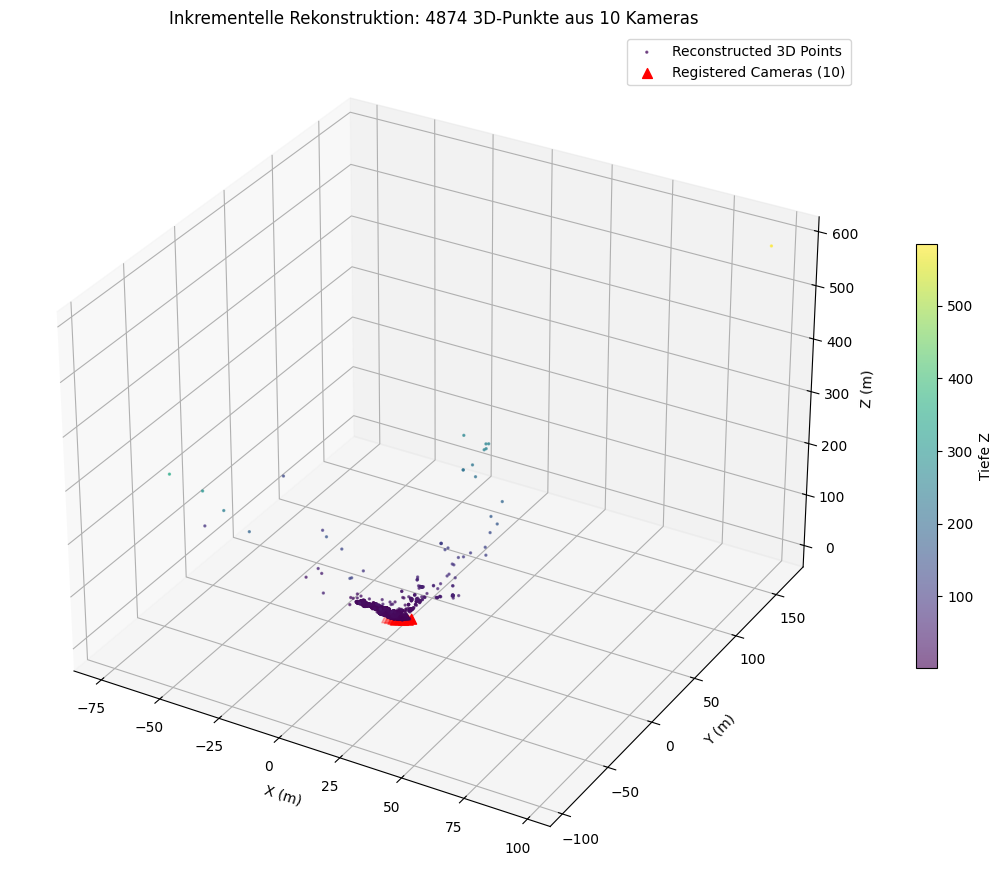

Successfully exported 4874 3D points to /home/semi/projects/propyläen_3d_reconstruct/outputs/final_reconstruction.ply
3D-Modell erfolgreich gespeichert unter: /home/semi/projects/propyläen_3d_reconstruct/outputs/final_reconstruction.ply


In [9]:
import matplotlib.pyplot as plt
import numpy as np

# ---------------------------------------------------------
# 1. 3D Plot von Punktwolke und allen Kameras
# ---------------------------------------------------------
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

# A. Visualisiere die globale 3D-Punktwolke (farblich nach Tiefe Z codiert)
scatter = ax.scatter(
    global_point_cloud[:, 0],
    global_point_cloud[:, 1],
    global_point_cloud[:, 2],
    c=global_point_cloud[:, 2],
    cmap="viridis",
    s=2,
    alpha=0.6,
    label="Reconstructed 3D Points",
)

# B. Plotten aller registrierten Kamerapositionen (Weltkoordinaten: C = -R^T * T)
cam_centers = []
for idx, cam_data in registered_cameras.items():
  R_c = cam_data["R"]
  T_c = cam_data["T"]
  # Berechnung des optischen Zentrums der Kamera im Weltkoordinatensystem
  C = (-R_c.T @ T_c).ravel()
  cam_centers.append(C)

cam_centers = np.array(cam_centers)

# Kameras als rote Pyramiden/Punkte plotten
ax.scatter(
    cam_centers[:, 0],
    cam_centers[:, 1],
    cam_centers[:, 2],
    c="red",
    s=50,
    marker="^",
    label=f"Registered Cameras ({len(cam_centers)})",
)

# Trajektorie der Kamerafahrt zeichnen
ax.plot(
    cam_centers[:, 0],
    cam_centers[:, 1],
    cam_centers[:, 2],
    c="red",
    linestyle="--",
    alpha=0.5,
)

# Achsenbeschriftungen und Layout
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.set_zlabel("Z (m)")
ax.set_title(
    f"Inkrementelle Rekonstruktion: {len(global_point_cloud)} 3D-Punkte aus"
    f" {len(registered_cameras)} Kameras"
)
ax.legend()
fig.colorbar(scatter, ax=ax, shrink=0.5, label="Tiefe Z")

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 2. Export der Punktwolke als .ply-Datei
# ---------------------------------------------------------
output_file = PROJECT_ROOT / "outputs" / "final_reconstruction.ply"
export_ply(str(output_file), global_point_cloud)
print(f"3D-Modell erfolgreich gespeichert unter: {output_file}")